# Lançamento

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import import_ipynb
import forcas_foguete as ff
import copy

0.0 | 0.0 | 177509.40123957643
Mach = 1.1
CD = 0.429
-0.0 | -0.0 | -0.0


<string>:42: RuntimeWarning: invalid value encountered in sqrt


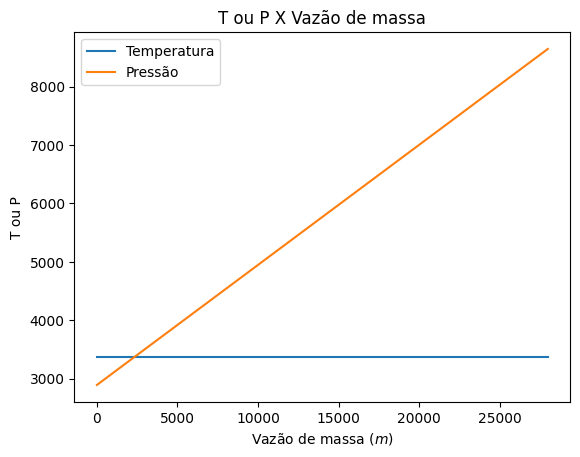

ModuleSpec(name='forcas_foguete', loader=<import_ipynb.NotebookLoader object at 0x00000233E0E974D0>, origin='forcas_foguete.ipynb')

In [14]:
import importlib

importlib.reload(ff)

## Exaustão constante

In [15]:
dt = 1/60

foguete = copy.deepcopy(ff.foguete)

Kvm = 14_000


foguete.update({
    "vm": Kvm
})

foguete

R = [foguete["p"]]
V = [foguete["v"]]

resultante = ff.resultante_foguete(foguete)
a = [resultante / foguete["mt"]]

vm = [foguete["vm"]]
m = [foguete["mt"]]

def atualiza_foguete(foguete, t, dt=1/60):
    resultante = ff.resultante_foguete(foguete)
    
    a.append(resultante / foguete["mt"])
    
    V.append(V[t-1] + (dt / 2) * (a[t-1] + a[t]))
        
    R.append(R[t-1] + (dt / 2) * (V[t-1] + V[t]))
    
    if R[-1][2] < 0:
        R[-1][2] = 0
        V[-1][2] = 0
        
    vm.append(vm[t-1])
    
    m.append(m[t-1] - (dt / 2) * (vm[t-1] + vm[t]))
    
    novo_foguete = foguete.copy()
    novo_foguete.update({
        "v": V[t],
        "p": R[t],
        "vm": vm[t],
        "mt": m[t],
        "cg": foguete["cg"] + m[t-1] - m[t]
    })
    
    return novo_foguete

# print(f"""
# {R=}
# {V=}
# {a=}
# {vm=}
# {m=}   
# """) 

while foguete["cg"]<=foguete["ct"]:
    foguete = atualiza_foguete(foguete, len(a))

foguete

{'estagio': 0,
 'phi': 1.5707963267948966,
 'theta': 0,
 'v': array([0.00000000e+00, 6.20304486e-13, 8.42452408e+03]),
 'V': np.float64(14776.2624),
 'A': np.float64(289.6015),
 'mt': np.float64(188979.33333309513),
 'ct': np.int64(2687630),
 'cg': np.float64(2687766.666666905),
 'c': 1,
 'vm': 14000,
 'p': array([0.00000000e+00, 3.09588457e-11, 3.44017131e+05])}

In [16]:
print(f"""
{a[-1] = }
{R[-1] = }

""")


a[-1] = array([0.00000000e+00, 1.83015655e-14, 2.90061323e+02])
R[-1] = array([0.00000000e+00, 3.09588457e-11, 3.44017131e+05])


